# KEEP baseline and ancestor roll-up variants

**Question:** With the same complete histories, depth-five eligibility and two-diagnosis presence rule, how do selecting one parent and including Disease change patient-level co-occurrence relationships?

This notebook establishes the **project baseline using the existing PyHealth API** and changes one choice at a time. The public OMOP factory and KEEP counter produce every measured matrix. An independent example counter and hand-derived patient sets check those results exactly. Inputs are invented; results establish the tested synthetic contract, not author-artifact parity, clinical effects or published-result replication.

The [hierarchy notebook](keep_ancestor_rollup_ablation.ipynb) explains traversal and scale. The [closure/rescue study](keep_ancestor_rollup_ablation_expanded.ipynb) explores a separate construction question. Its cutoff-two fixture and `first_retained` reference are not the baseline for this notebook.

## 1. Baseline and isolated interventions

| Setting | Dense baseline | Single-parent variant | Root-inclusive variant |
|---|---|---|---|
| Target selection | `all_retained`: all eligible parents/ancestors for deep sources | Exactly one dense candidate per mapped source concept | `all_retained` |
| Root eligibility | Disease `4274025` excluded | Excluded | Included via API `include_root=True` |
| Minimum root depth cutoff | 5 | 5 | 5 |
| Presence | At least 2 distinct diagnosis rows after roll-up | Same | Same |
| Traversal | API default `direct`; rescue off | Same | Same |
| Retained source | Identity mapping | Identity mapping | Identity mapping |

Single-parent selection ranks candidates by shortest upward path through the selected direct graph, then **numeric** OMOP concept ID. `first_retained` can return several parents and is not this intervention. Selection is per mapped concept; ICD one-to-many conversion is not collapsed.

Root inclusion uses the existing API behavior. It does not expand retained diagnoses to every ancestor, and it does not give Disease to every patient. Root presence still needs two distinct supporting diagnoses.

All arms explicitly use diagnostic `on_unmapped="empty"` so excluded-root and unknown rows remain accounted for in the fixed cohort. This differs from the factory's fail-fast default `error`; it is held fixed across arms and does not silently drop patients. Occurrence thresholds 1/3 belong in a later isolated notebook. Admissions are deferred; diagnosis source is excluded. Depth ablation belongs to the peer's study.

In [1]:
from pathlib import Path
import inspect
import subprocess
import sys
import warnings
warnings.filterwarnings("ignore", message="`torch.jit.script` is deprecated.*", category=FutureWarning)
warnings.filterwarnings("ignore", message="Sparse invariant checks.*", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found.*")
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
assert (ROOT_DIR / "examples" / "keep_ancestor_rollup_variants.py").is_file()
sys.path.insert(0, str(ROOT_DIR))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from examples.keep_ancestor_rollup_variants import ROOT, ARMS, run_study
from examples.keep_ancestor_rollup_ablation_utils import trace_pair, validate_matrix
from pyhealth.tasks import build_keep_cooccurrence
assert Path(inspect.getfile(build_keep_cooccurrence)).resolve() == ROOT_DIR / "pyhealth/tasks/keep.py"
print("Python:", sys.version.split()[0])
print("Checkout:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT_DIR, text=True).strip())
print("Working tree modified:", bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT_DIR, text=True).strip()))
study = run_study()
assert study["public_counter_agreement"] and study["hand_oracle_passed"]
print("Passed: three public-counter matrices, independent counter agreement, hand-derived oracle, and every pair trace.")
display(pd.DataFrame([study["settings"]]).drop(columns=["comparison_axes"]).T.rename(columns={0:"value"}))

Python: 3.12.12
Checkout: 24229ec603835783ddf3b801cfdb5bcfdbfb4aea
Working tree modified: True
Passed: three public-counter matrices, independent counter agreement, hand-derived oracle, and every pair trace.


,value
baseline,dense
root,4274025
max_depth,5
target_policy,all_retained
include_root,False
path_source,direct
rescue,False
presence_threshold,2
on_unmapped,empty
single_parent_rule,"shortest upward direct path, then numeric conc..."


## 2. Fixture and correctness controls

All non-root IDs are invented OMOP-format concept labels. `CONCEPT_ANCESTOR` is coherently derived from this tiny DAG. The public factory reads its minimum root depths; deep sources remain available beyond the cutoff.

```
Disease → 101 → 102 → 103 → 104 → 105 ─┐
                                     ├→ 900 → 901
Disease → 201 → 202 → 203 → 204 → 205 ─┘
Disease → 301                            unused eligible concept
```

`900` has depth six and `901` depth seven. Dense mapping returns ten non-root ancestors. Single-parent selects `105`, at distance one from `900` and two from `901`; equal-distance `205` loses the numeric-ID tie break.

The ten patients include two deep diagnoses, two different deep diagnoses, retained-only histories, a copied diagnosis, a single deep diagnosis, an empty history, unknown concepts, explicit root diagnoses, and a threshold control (`900` once plus retained `105` once). Both diagnoses in each history can share one admission: this experiment counts diagnosis rows.

The helper asserts every matrix coordinate from hand-derived patient sets and reconciles patient contributions for every pair in both comparisons. Copied rows and many targets from one diagnosis cannot establish presence.

In [2]:
target_rows = [{"arm": arm, **row} for arm in ARMS for row in study["targets"][arm]]
display(pd.DataFrame(target_rows))
presence = pd.DataFrame([
    {"patient": row["patient_id"], "arm": arm, "present": row["present"], "occurrences": row["occurrences"]}
    for arm in ARMS for row in study["traces"][arm]
])
display(presence.pivot(index="patient", columns="arm", values="present"))
for arm in ARMS:
    controls = {row["patient_id"]: row for row in study["traces"][arm]}
    assert all(controls[p]["present"] == [] for p in ("p4", "p6", "p7", "p8"))
    assert controls["p10"]["present"] == ["105"]
print("Copied/single-diagnosis controls remain absent; p10 never gains root presence.")

,arm,source,targets,source_depth,reason
0,dense,900,"(101, 102, 103, 104, 105, 201, 202, 203, 204, ...",6.0,rolled_up
1,dense,901,"(101, 102, 103, 104, 105, 201, 202, 203, 204, ...",7.0,rolled_up
2,dense,105,"(105,)",5.0,retained
3,dense,4274025,(),0.0,no_target
4,dense,999999,(),NaN,unknown_code
5,single_parent,900,"(105,)",6.0,rolled_up
6,single_parent,901,"(105,)",7.0,rolled_up
7,single_parent,105,"(105,)",5.0,retained
8,single_parent,4274025,(),0.0,no_target
9,single_parent,999999,(),NaN,unknown_code


arm,dense,root_inclusive,single_parent
patient,,,
p1,"[101, 102, 103, 104, 105, 201, 202, 203, 204, ...","[101, 102, 103, 104, 105, 201, 202, 203, 204, ...",[105]
p10,[105],[105],[105]
p2,"[101, 102, 103, 104, 105, 201, 202, 203, 204, ...","[101, 102, 103, 104, 105, 201, 202, 203, 204, ...","[105, 205]"
p3,"[105, 205]","[105, 205]","[105, 205]"
p4,[],[],[]
p5,"[101, 102, 103, 104, 105, 201, 202, 203, 204, ...","[101, 102, 103, 104, 105, 201, 202, 203, 204, ...",[105]
p6,[],[],[]
p7,[],[],[]
p8,[],[],[]


Copied/single-diagnosis controls remain absent; p10 never gains root presence.


## 3. Population, graph and pair-count measurements

Keep all ten patients, including empty and unmapped histories, in every denominator. Report patients with present targets as an outcome.

The native eligible universe has 11 concepts without Disease and 12 with it. The public counter first uses each arm's exact native axes. For comparison, all matrices are then aligned to the **same 12-concept union**, padding Disease with a zero row/column in the root-exclusive arms. No counts change during alignment. Pair density therefore uses the same 66 possible unordered pairs in every arm.

Traversal nodes/edges describe the fixed uncut ontology. Eligible induced edges describe its edges with both endpoints eligible; they are not projected patient graphs. Single-parent changes representation targets rather than deleting ontology nodes.

In [3]:
aggregates = pd.DataFrame(study["aggregates"]).T
columns = ["patients", "patients_with_present_targets", "unique_diagnoses", "mapped_diagnoses",
           "traversal_nodes", "traversal_edges", "eligible_targets", "eligible_induced_edges",
           "conditions_present", "comparison_axes", "possible_pairs", "observed_pairs", "pair_density",
           "pair_mass", "entropy_bits", "normalized_entropy"]
display(aggregates[columns].T)
summary = pd.DataFrame({arm: report["summary"] for arm, report in study["comparisons"].items()}).T
display(summary)
assert study["comparisons"]["root_inclusive"]["summary"]["nonroot_pair_absolute_delta"] == 0
print("Root inclusion leaves every non-root raw count unchanged in this fixture.")

,dense,single_parent,root_inclusive
patients,10,10,10
patients_with_present_targets,5,5,6
unique_diagnoses,20,20,20
mapped_diagnoses,16,16,18
traversal_nodes,14,14,14
traversal_edges,14,14,14
eligible_targets,11,11,12
eligible_induced_edges,8,8,11
conditions_present,10,2,11
comparison_axes,12,12,12


,observed_pair_union,changed_count_pairs,gained_pairs,lost_pairs,absolute_count_delta,changed_ppmi_pairs,undefined_ppmi_deltas,changed_pair_fraction,global_pair_mass_jsd,root_pair_absolute_delta,nonroot_pair_absolute_delta
single_parent,45.0,45.0,0.0,44.0,134.0,0.0,44.0,1.000000,0.903659,0.0,134.0
root_inclusive,55.0,10.0,10.0,0.0,30.0,0.0,10.0,0.181818,0.096847,30.0,0.0


Root inclusion leaves every non-root raw count unchanged in this fixture.


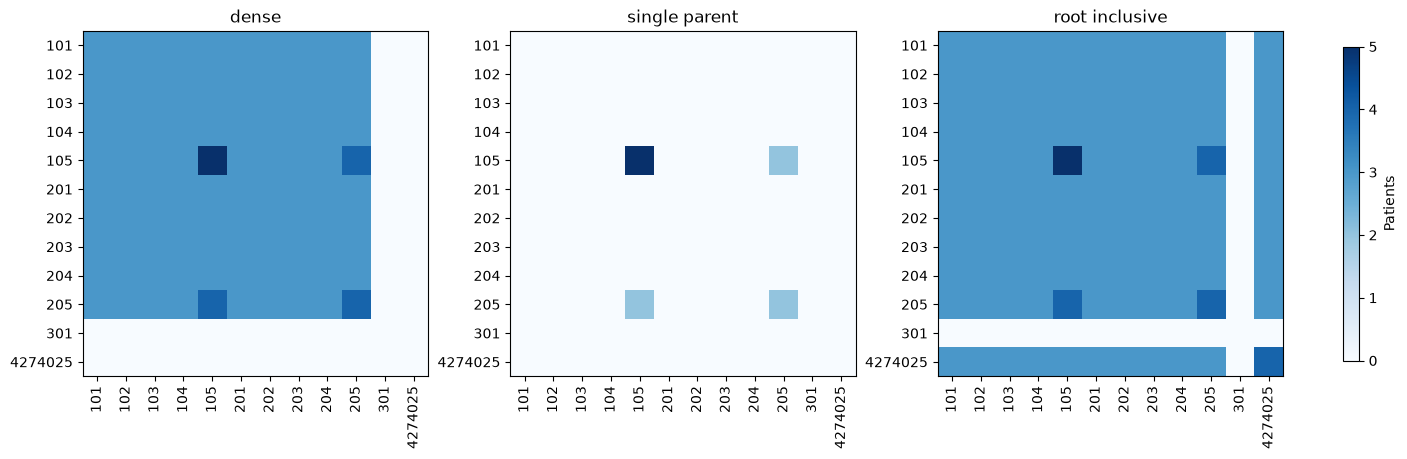

In [4]:
axes = study["settings"]["comparison_axes"]
frames = {}
for arm, matrix in study["matrices"].items():
    values = validate_matrix(matrix)
    frames[arm] = pd.DataFrame([[values.get((i,j),0) for j in axes] for i in axes], index=axes, columns=axes)
fig, plots = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
maximum = max(frame.to_numpy().max() for frame in frames.values())
for axis, arm in zip(plots, ARMS):
    picture = axis.imshow(frames[arm], vmin=0, vmax=maximum, cmap="Blues")
    axis.set(title=arm.replace("_", " "), xticks=range(len(axes)), yticks=range(len(axes)),
             xticklabels=axes, yticklabels=axes)
    axis.tick_params(axis="x", rotation=90)
fig.colorbar(picture, ax=plots, shrink=0.8, label="Patients")
plt.show()

## 4. Reconciled effects and controls

For single-parent, pair `105,205` falls from four patients to two: deep diagnoses lose `205`, but retained `205` diagnoses still support it. For root-inclusive, pair `105,Disease` is born in three patients. Patient `p10` remains unchanged because its one deep diagnosis gives only one root occurrence. Patient `p3` has retained-only diagnoses and never gains Disease.

In [5]:
for arm, pair in (("single_parent", ("105", "205")), ("root_inclusive", ("105", ROOT))):
    witnesses = trace_pair(study["traces"]["dense"], study["traces"][arm], *pair)
    left, right = [validate_matrix(study["matrices"][name]).get(pair, 0) for name in ("dense", arm)]
    assert sum(w["pair_delta"] for w in witnesses) == right-left
    print(arm, pair, f"{left} → {right}")
    diagnosis_rows = []
    for witness in witnesses:
        for side in ("before", "after"):
            for diagnosis in witness[side]["diagnoses"]:
                diagnosis_rows.append({"patient": witness["patient_id"], "side": side,
                                       "diagnosis": diagnosis["diagnosis_id"], "source": diagnosis["codes"],
                                       "targets": diagnosis["targets"], "pair_delta": witness["pair_delta"]})
    with pd.option_context("display.max_colwidth", 120):
        display(pd.DataFrame(diagnosis_rows))

display(presence[presence["patient"].isin(["p3", "p4", "p7", "p10"])])

single_parent ('105', '205') 4 → 2


,patient,side,diagnosis,source,targets,pair_delta
0,p1,before,x1,[900],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",-1
1,p1,before,x2,[900],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",-1
2,p1,after,x1,[900],[105],-1
3,p1,after,x2,[900],[105],-1
4,p5,before,x,[900],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",-1
5,p5,before,y,[901],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",-1
6,p5,after,x,[900],[105],-1
7,p5,after,y,[901],[105],-1


root_inclusive ('105', '4274025') 0 → 3


,patient,side,diagnosis,source,targets,pair_delta
0,p1,before,x1,[900],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",1
1,p1,before,x2,[900],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",1
2,p1,after,x1,[900],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205, 4274025]",1
3,p1,after,x2,[900],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205, 4274025]",1
4,p2,before,b1,[205],[205],1
5,p2,before,b2,[205],[205],1
6,p2,before,y1,[901],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",1
7,p2,before,y2,[901],"[101, 102, 103, 104, 105, 201, 202, 203, 204, 205]",1
8,p2,after,b1,[205],[205],1
9,p2,after,b2,[205],[205],1


,patient,arm,present,occurrences
2,p3,dense,"[105, 205]","{'105': 2, '205': 2}"
3,p4,dense,[],"{'101': 1, '102': 1, '103': 1, '104': 1, '105'..."
6,p7,dense,[],"{'101': 1, '102': 1, '103': 1, '104': 1, '105'..."
9,p10,dense,[105],"{'101': 1, '102': 1, '103': 1, '104': 1, '105'..."
12,p3,single_parent,"[105, 205]","{'105': 2, '205': 2}"
13,p4,single_parent,[],{'105': 1}
16,p7,single_parent,[],{'105': 1}
19,p10,single_parent,[105],{'105': 2}
22,p3,root_inclusive,"[105, 205]","{'105': 2, '205': 2}"
23,p4,root_inclusive,[],"{'101': 1, '102': 1, '103': 1, '104': 1, '105'..."


## 5. Associations, distribution shift and concentration

All pair statistics exclude prevalence diagonals. Raw counts and support are retained without smoothing or filtering.

- **PPMI:** `max(0, ln(N Xij / (Xii Xjj)))`. Zero marginals are undefined; an unobserved pair with positive marginals uses zero as a clipping convention.
- **NPMI:** `ln(N Xij / (Xii Xjj)) / -ln(Xij/N)`. Unlike PPMI it retains negative associations. Unobserved pairs and `Xij=N` are undefined; no perfect-association convention is imposed on the latter `0/0` case.
- **Entropy:** base-2 Shannon entropy of unordered pair-count mass, normalized by `log2(66)` for the fixed comparison universe. Zero mass is undefined.
- **Global JSD:** base-2 divergence of the two pair-mass distributions on aligned coordinates. This measures the whole distribution; the existing **row JSD** measures a particular concept's normalized relationship profile. Both are undefined when an input has no mass.
- **Concentration:** top ceiling(1%) count-mass share and HHI, with observed pair count and total mass. GloVe log targets and weights retain fixed analysis settings `x_max=50`, `alpha=0.75`; these are not a trained loss or an assertion about the trainer's adaptive cutoff.

The common-support table compares the same positive pairs in both arms. Births/deaths are reported separately, and undefined NPMI/PPMI values are preserved. Changing support can otherwise create a misleading median comparison.

In [6]:
display(pd.DataFrame({arm: r["common_support"] for arm, r in study["comparisons"].items()}).T)
for arm, report in study["comparisons"].items():
    print("Dense →", arm)
    pairs = pd.json_normalize(report["pairs"])
    display(pairs[["i", "j", "status", "before.count", "after.count", "count_delta",
                   "before.ppmi", "after.ppmi", "before.npmi", "after.npmi", "npmi_delta"]].round(5))
    display(pd.DataFrame(report["concentration"]).T)
    display(pd.DataFrame(report["profiles"]).round(5))

,pairs,before_ppmi_defined,before_ppmi_median,before_npmi_defined,before_npmi_median,after_ppmi_defined,after_ppmi_median,after_npmi_defined,after_npmi_median
single_parent,1.0,1.0,0.693147,1.0,0.756471,1.0,0.693147,1.0,0.430677
root_inclusive,45.0,45.0,1.203973,45.0,1.000000,45.0,1.203973,45.0,1.000000


Dense → single_parent


,i,j,status,before.count,after.count,count_delta,before.ppmi,after.ppmi,before.npmi,after.npmi,npmi_delta
0,101,102,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN
1,101,103,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN
2,101,104,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN
3,101,105,lost,3,0,-3,0.69315,NaN,0.57572,NaN,NaN
4,101,201,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN
5,101,202,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN
6,101,203,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN
7,101,204,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN
8,101,205,lost,3,0,-3,0.91629,NaN,0.76106,NaN,NaN
9,102,103,lost,3,0,-3,1.20397,NaN,1.00000,NaN,NaN


,observed_pairs,possible_pairs,pair_mass,top_pair_count,top_1pct_share,hhi
before,45.0,66.0,136.0,1.0,0.029412,0.022275
after,1.0,66.0,2.0,1.0,1.000000,1.000000


,concept_id,count_cosine,count_jsd,ppmi_cosine,ppmi_jsd
0,101,NaN,NaN,NaN,NaN
1,102,NaN,NaN,NaN,NaN
2,103,NaN,NaN,NaN,NaN
3,104,NaN,NaN,NaN,NaN
4,105,0.4264,0.68939,0.33333,0.73945
5,201,NaN,NaN,NaN,NaN
6,202,NaN,NaN,NaN,NaN
7,203,NaN,NaN,NaN,NaN
8,204,NaN,NaN,NaN,NaN
9,205,0.4264,0.68939,0.25837,0.78246


Dense → root_inclusive


,i,j,status,before.count,after.count,count_delta,before.ppmi,after.ppmi,before.npmi,after.npmi,npmi_delta
0,101,102,shared,3,3,0,1.20397,1.20397,1.00000,1.00000,0.0
1,101,103,shared,3,3,0,1.20397,1.20397,1.00000,1.00000,0.0
2,101,104,shared,3,3,0,1.20397,1.20397,1.00000,1.00000,0.0
3,101,105,shared,3,3,0,0.69315,0.69315,0.57572,0.57572,0.0
4,101,201,shared,3,3,0,1.20397,1.20397,1.00000,1.00000,0.0
5,101,202,shared,3,3,0,1.20397,1.20397,1.00000,1.00000,0.0
6,101,203,shared,3,3,0,1.20397,1.20397,1.00000,1.00000,0.0
7,101,204,shared,3,3,0,1.20397,1.20397,1.00000,1.00000,0.0
8,101,205,shared,3,3,0,0.91629,0.91629,0.76106,0.76106,0.0
9,101,4274025,gained,0,3,3,NaN,0.91629,NaN,0.76106,NaN


,observed_pairs,possible_pairs,pair_mass,top_pair_count,top_1pct_share,hhi
before,45.0,66.0,136.0,1.0,0.029412,0.022275
after,55.0,66.0,166.0,1.0,0.024096,0.018217


,concept_id,count_cosine,count_jsd,ppmi_cosine,ppmi_jsd
0,101,0.94868,0.05190,0.96529,0.04314
1,102,0.94868,0.05190,0.96529,0.04314
2,103,0.94868,0.05190,0.96529,0.04314
3,104,0.94868,0.05190,0.96529,0.04314
4,105,0.95248,0.05016,0.98152,0.03121
5,201,0.94868,0.05190,0.96529,0.04314
6,202,0.94868,0.05190,0.96529,0.04314
7,203,0.94868,0.05190,0.96529,0.04314
8,204,0.94868,0.05190,0.96529,0.04314
9,205,0.95248,0.05016,0.97363,0.03732


## 6. Interpretation and remaining scope

These synthetic results isolate two representation interventions under the agreed baseline. Single-parent removes ancestor-induced pairs. Root inclusion adds root-related pair mass while non-root counts stay unchanged here; normalized global distributions can change even when those non-root counts do not. Disease is not universally present.

The oracle, counter agreement and traces establish this fixture's correctness. Cohort exposure, clinical validity, learned embeddings and exact author-artifact parity are unmeasured. A larger common cohort can change effect sizes and which support categories occur.

**Follow-up:** keep depth with the peer; study diagnosis-row thresholds 1 and 3 in an isolated notebook. Admission-based presence remains deferred. Diagnosis-source ablation is outside the current study. The closure/rescue notebook remains a separate extension, held fixed here rather than crossed into these two comparisons.

Run both headless and notebook forms from this checkout with a Python 3.12+ environment containing the graph extra, pandas, matplotlib, nbclient/nbconvert and ipykernel. Choose a fresh output directory:

```sh
python -m examples.keep_ancestor_rollup_variants --output /tmp/keep-rollup-variants-new
python -m pytest tests/core/test_keep_rollup_variants.py tests/core/test_keep_rollup_ablation_example.py
python -m nbconvert --to notebook --execute examples/keep_ancestor_rollup_variants.ipynb --output-dir /tmp --output keep-rollup-variants-executed.ipynb
```

The report records source/table/history hashes, settings, all three matrices, target outcomes, diagnosis/presence traces and both comparison reports. Native axes are aligned only after public counting. The helper never discovers clinical inputs or changes production defaults.

In [7]:
print("Source SHA256:")
display(pd.Series(study["source_sha256"], name="sha256").to_frame())
print("Synthetic table SHA256:")
display(pd.Series(study["input_sha256"], name="sha256").to_frame())
print("Histories SHA256:", study["histories_sha256"])
print("Completed: dense baseline, single-parent, root-inclusive; all correctness assertions passed.")

Source SHA256:


,sha256
factory,29ef15ccd7ea1d989f9fffc8779f7b9edb94dd2b6bb1b6...
counter,29ef15ccd7ea1d989f9fffc8779f7b9edb94dd2b6bb1b6...
processor,a24e881f4ec42383b9fedd2ece468c7637d9eb5f6d3cd2...
study,0a414d1ef585e81c814d0ec95b1b6accb27159f17566bf...
metrics,f6082e409ad0c5b402027ae1fa80bdb801f4c07bedd127...


Synthetic table SHA256:


,sha256
CONCEPT.csv,9fc3f85bb0dff8ba47a1f76980c8861517a727db1a4f6b...
CONCEPT_ANCESTOR.csv,396e3a7008e33551b947e9c97e22f2ef627a425c7d827d...
CONCEPT_RELATIONSHIP.csv,27cb23517f3b09b8b04a45a8df1aabc53c5072b404a482...


Histories SHA256: 3ca7292c597453f286591ad582d3474fa869a9405c82981046bcd0b20ec5d9bf
Completed: dense baseline, single-parent, root-inclusive; all correctness assertions passed.
